# Simon's Algorithm

> The objective is to find period ($p$), given an unknown oracle ($f$)

Since p
can be any number between 00 . . . 0 and 11 . . . 1, we have to try ∼ $2^n$ possibilities classically before we hit the right number. It is shown below that the
number of trials required to ﬁnd p is reduced to $O(n)$ if Simon’s algorithm is
employed.

The considerstion for the algorithm are

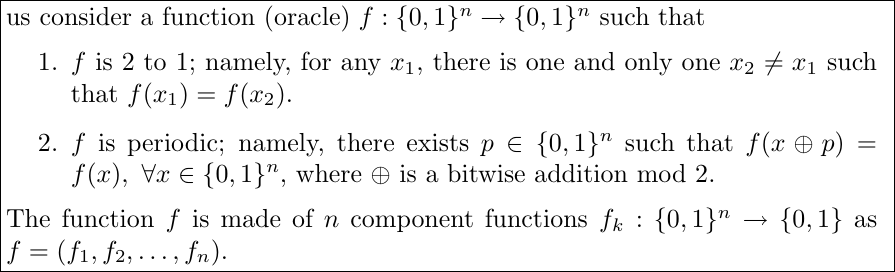

## The algorithm works as

1. Initialize: Prepare two $n$-qubit registers in $|0\rangle|0\rangle$.

2. Superposition: Apply Hadamard gates to the first register:
$$
\frac{1}{\sqrt{2^n}}\sum_{x\in{0,1}^n}|x\rangle|0\rangle
$$

3. Oracle: Apply $U_f$ to evaluate $f(x)$ in superposition:
$$
\frac{1}{\sqrt{2^n}}\sum_x|x\rangle|f(x)\rangle
$$

4. Measure the second register: Obtain an output $f(x_0)$, collapsing the first register into:
$$
\frac{|x_0\rangle+|x_0\oplus p\rangle}{\sqrt2
}
$$

5. Apply Hadamard: Apply $H^{\otimes n}$ to the first register, causing interference that eliminates outcomes where $p\cdot y=1$.

6. Measure the first register: Obtain a bit string $y$ satisfying:
$$
p\cdot y=0\pmod2
$$

7. Repeat: Repeat steps 1–6 to collect enough linearly independent equations.

8. Solve classically: Solve the collected equations over $\mathbb F_2$ using Gaussian elimination to recover the nonzero hidden period $p$.

## Implementation

Simon's algorithm assumes that we have access to a function or oracle f, and it has a hidden period p nonzero bit string that satisfies $f(x) = f(x \oplus p)$

Let, p = 100 \
x = 001 \
then, $x \oplus p$ = 111 \
so, $f(001) = f(111)$

In [40]:
# Import packages

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

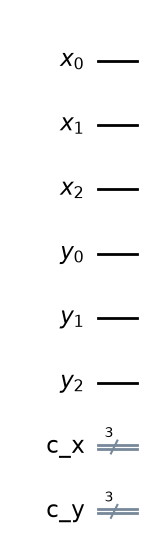

In [41]:
# Initialize the registers of n qubits, 
# need quantum register for calculation and classical regiser to store measurement result
# Initially, The quantum processor prepares each qubit in the computational basis state |0>

n = 3

# n bit i/p and o/p quantum register
X = QuantumRegister(n, "x")
Y = QuantumRegister(n, "y")

# classical registers
c_x = ClassicalRegister(n, "c_x")
c_y = ClassicalRegister(n, "c_y")

qc = QuantumCircuit(X, Y, c_x, c_y)

qc.draw("mpl") # mpl means Matplotlib drawing

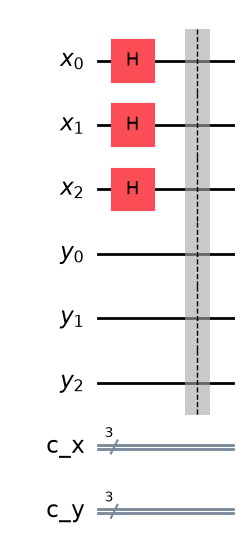

In [42]:
# Apply Hadamard gates to input register only to create superposition

qc.h(X)

# Draw a seperator after H gate
qc.barrier()

qc.draw("mpl")

In [43]:
# Construct and apply the Oracle, f
# This is reversible and satisfy the Simon promise

def simon_oracle(p):
    n = len(p)
    X = QuantumRegister(n, "x")
    Y = QuantumRegister(n, "y")

    oracle = QuantumCircuit(X, Y, name="Oracle")

    # Copy x into the o/p register |x>|000> -> |x>|x>
    for i in range(n):
        oracle.cx(X[i], Y[i])

    pivot = p.index("1")

    # Qiskit uses little-endian qubit indexing
    pivot_qubit = n - 1 - pivot

    # Apply contolled XOR of p into the output gives us the desired two-to-one function
    for j in range(n):
        if p[j] == "1":
            target = n - 1 - j
            oracle.cx(X[pivot_qubit], Y[target])

    return oracle

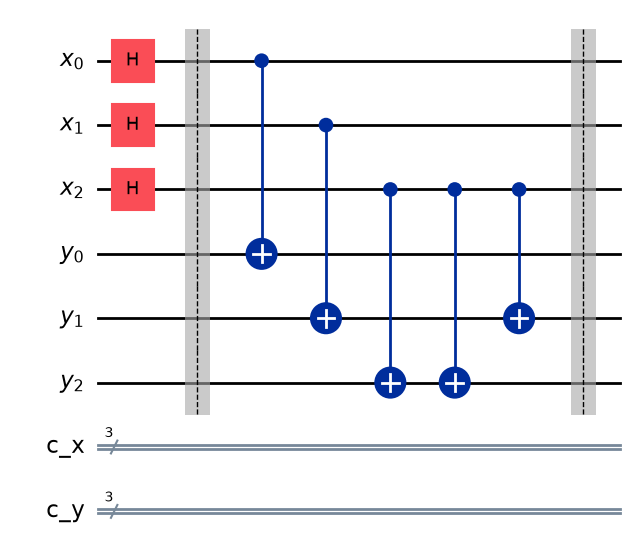

In [44]:
# Apply the oracle with period p

p = "110"
oracle = simon_oracle(p)
qc.compose(oracle, inplace=True)
qc.barrier()
qc.draw("mpl")

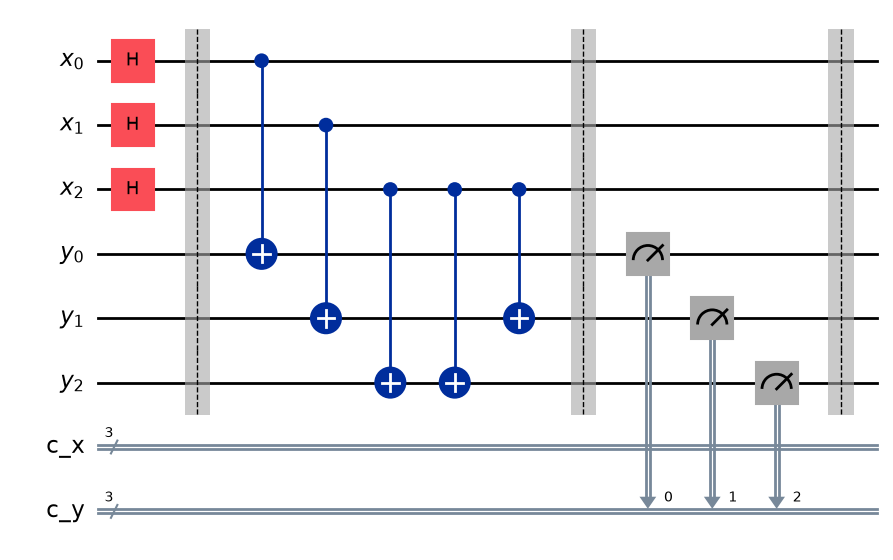

In [45]:
# Measure the output register

qc.measure(Y, c_y)
qc.barrier()
qc.draw("mpl")

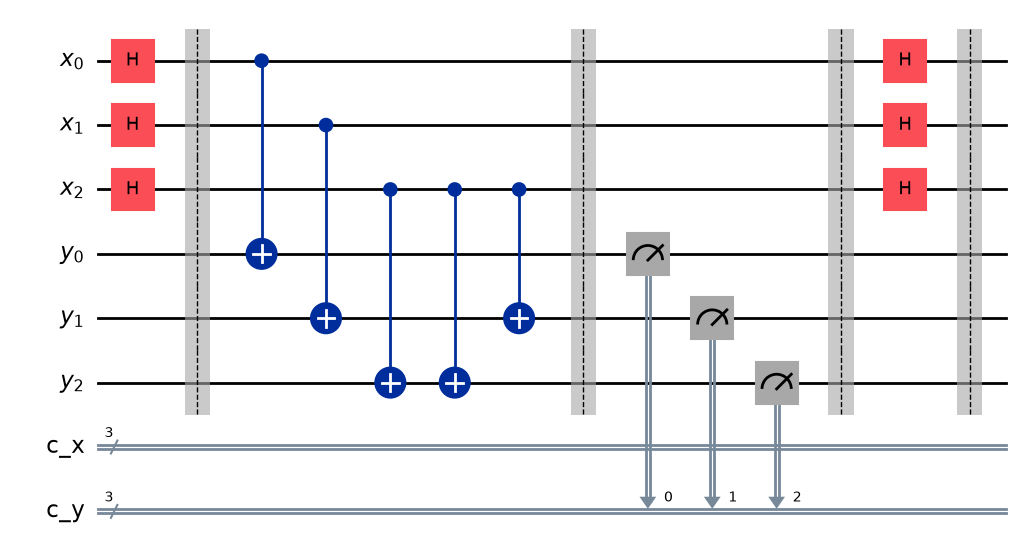

In [46]:
# Apply Hadamard gate to the imput register

qc.h(X)
qc.barrier()
qc.draw("mpl")

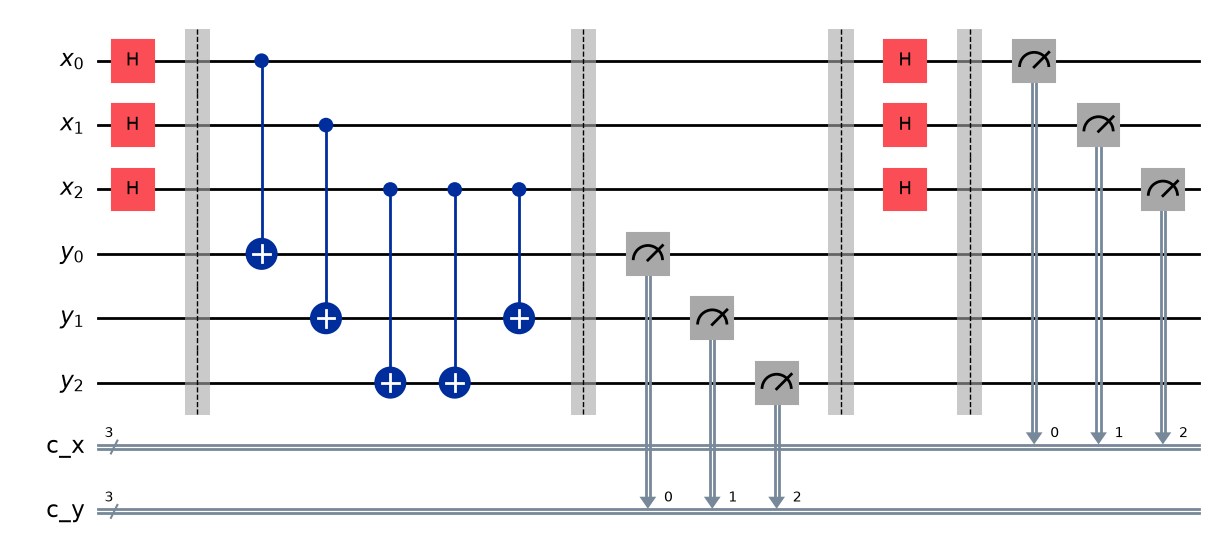

In [47]:
# Now measure the imput register

qc.measure(X, c_x)
qc.draw("mpl")

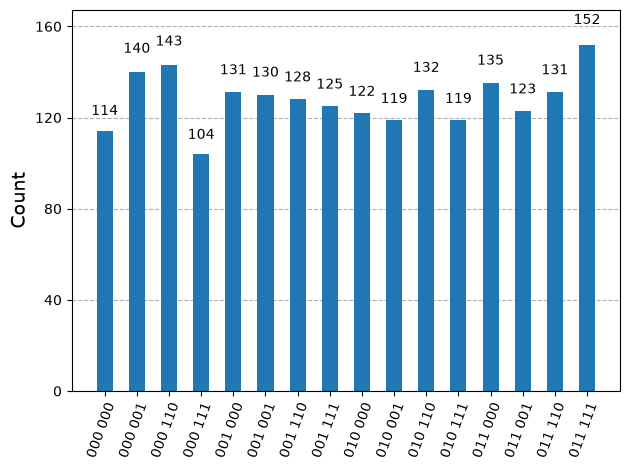

In [48]:
# Now execute the circuit repetedly

simulator = AerSimulator()
compiled = transpile(qc, simulator)

result = simulator.run(
    compiled,
    shots=2048
).result()

counts = result.get_counts()
plot_histogram(counts)

In [49]:
# Recover the hidden period using Gaussian elimination method
# This is the classical part

def recover_period(ys, n):

    # Construct matrix Y over GF(2)
    A = [
        [(y >> (n - 1 - j)) & 1 for j in range(n)]
        for y in ys
        if y != 0
    ]

    if not A:
        return None

    rows = len(A)
    pivot_columns = []
    pivot_row = 0

    # Gaussian elimination over GF(2)
    for col in range(n):

        # Find a row containing 1 in this column
        selected = next(
            (r for r in range(pivot_row, rows)
             if A[r][col] == 1),
            None
        )

        if selected is None:
            continue

        # Swap rows
        A[pivot_row], A[selected] = (
            A[selected], A[pivot_row]
        )

        # Eliminate this column in every other row
        for r in range(rows):
            if r != pivot_row and A[r][col] == 1:
                A[r] = [
                    a ^ b for a, b in zip(
                        A[r], A[pivot_row]
                    )
                ]

        pivot_columns.append(col)
        pivot_row += 1

        if pivot_row == rows:
            break

    # Find free columns
    free_columns = [
        col for col in range(n)
        if col not in pivot_columns
    ]

    # We need exactly one free variable
    if len(free_columns) != 1:
        return None

    # Set the free variable to 1
    solution = [0] * n
    free_col = free_columns[0]
    solution[free_col] = 1

    # Back-substitute using the reduced rows
    for r, pivot_col in enumerate(pivot_columns):
        solution[pivot_col] = A[r][free_col]

    return "".join(map(str, solution))

In [50]:
# Extract the measurement
# Qiskit displays classical registers in reverse register order
# With c_y and c_x, the rightmost group represents c_x

ys = []

for key, count in counts.items():
    measured_x = key.split()[-1]
    y = int(measured_x, 2)

    if y != 0:
        ys.append(y)

# Remove duplicate equations
ys = list(set(ys))

print("Measured y values:")
print([format(y, f"0{n}b") for y in ys])

Measured y values:
['001', '110', '111']


In [51]:
# Recover period

recovered_p = recover_period(ys, n)

print("Original period: ", p)
print("Recovered period:", recovered_p)

Original period:  110
Recovered period: 110
